# Практическая работа №1

## Настройка окружения и первый Notebook

**Датасет:** Palmer Penguins

**Цель:** загрузить датасет, изучить его структуру, проверить типы данных и пропуски, построить графики и сформулировать три наблюдения.

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/penguins.csv")

display(df.head())
print("Размер таблицы:", df.shape)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


Размер таблицы: (344, 7)


### Первичный осмотр данных

Датасет Palmer Penguins содержит 344 записи о пингвинах трёх видов: Adelie, Chinstrap и Gentoo.

В таблице представлены числовые и категориальные признаки. Числовые признаки описывают физические характеристики пингвинов, а категориальные — вид, остров и пол.

In [9]:
print("Информация о датасете:")
df.info()

print("\nТипы столбцов:")
print(df.dtypes)

Информация о датасете:
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB

Типы столбцов:
species                  str
island                   str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                      str
dtype: object


### Типы признаков

В датасете присутствуют два основных типа признаков.

**Числовые:** bill_length_mm, bill_depth_mm, flipper_length_mm, body_mass_g.

**Категориальные:** species, island, sex.

Такое разделение важно для дальнейшей предобработки, поскольку числовые и категориальные признаки обрабатываются разными методами.

In [10]:
print("Пропущенные значения по столбцам:")
print(df.isnull().sum())

print("\nКоличество дубликатов:")
print(df.duplicated().sum())

Пропущенные значения по столбцам:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

Количество дубликатов:
0


### Проверка качества данных

В датасете обнаружены пропущенные значения. Больше всего пропусков находится в столбце sex.

Также отсутствуют некоторые значения физических характеристик пингвинов.

На следующих практических занятиях можно будет обработать числовые пропуски медианой, а категориальные — отдельным значением Unknown.


### Описательная статистика

Метод describe() позволяет изучить основные характеристики числовых признаков: среднее значение, стандартное отклонение, минимумы, максимумы и квартили.

Для категориальных столбцов можно определить количество уникальных значений и наиболее часто встречающиеся категории.

Этот анализ помогает понять особенности данных перед построением моделей машинного обучения.

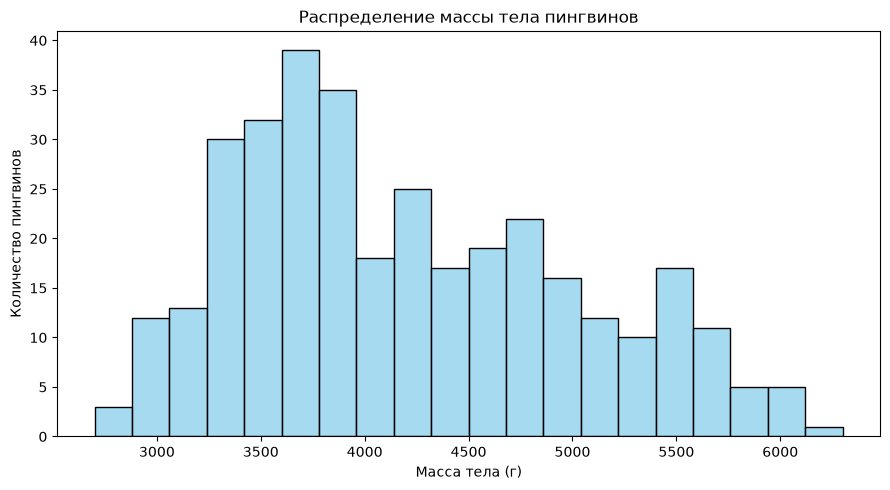

In [11]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="body_mass_g",
    bins=20,
    color="skyblue",
    edgecolor="black"
)

plt.title("Распределение массы тела пингвинов")
plt.xlabel("Масса тела (г)")
plt.ylabel("Количество пингвинов")

plt.tight_layout()
plt.show()

### Вывод по распределению массы тела

Масса тела пингвинов распределена неравномерно. В датасете присутствуют более лёгкие и более тяжёлые особи.

Такое распределение может быть связано с различиями между видами пингвинов. Для проверки этого предположения потребуется сравнить массу тела отдельно по видам.

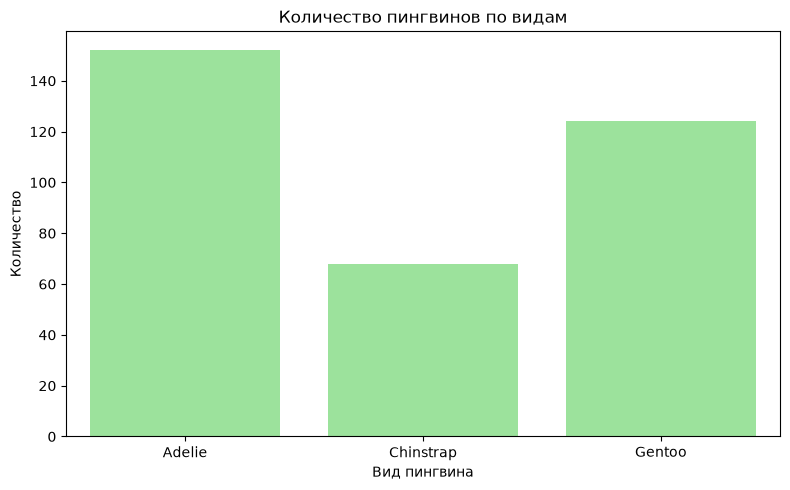

In [12]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="species",
    order=["Adelie", "Chinstrap", "Gentoo"],
    color="lightgreen"
)

plt.title("Количество пингвинов по видам")
plt.xlabel("Вид пингвина")
plt.ylabel("Количество")

plt.tight_layout()
plt.show()

### Вывод по видам пингвинов

В датасете больше всего пингвинов вида Adelie — 152.

Вид Gentoo представлен 124 записями, а Chinstrap — 68.

Распределение видов неравномерное. Это важно учитывать при дальнейшем построении моделей классификации.

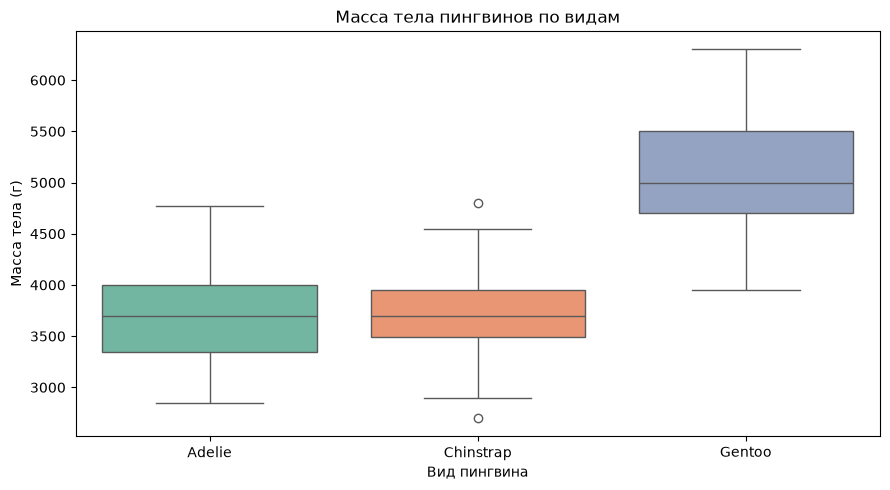

In [13]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="species",
    y="body_mass_g",
    hue="species",
    palette="Set2",
    legend=False
)

plt.title("Масса тела пингвинов по видам")
plt.xlabel("Вид пингвина")
plt.ylabel("Масса тела (г)")

plt.tight_layout()
plt.show()

### Вывод по сравнению массы тела

Пингвины вида Gentoo обычно тяжелее представителей Adelie и Chinstrap.

Распределения массы тела у Adelie и Chinstrap частично пересекаются.

Таким образом, вид пингвина связан с различиями в массе тела, но одной массы может быть недостаточно для точного определения вида.

## Основные наблюдения

**1. Неравномерное распределение видов.** В датасете больше всего пингвинов Adelie, а меньше всего Chinstrap. При последующей классификации необходимо учитывать различия в количестве объектов каждого класса.

**2. Различия в массе тела.** Пингвины Gentoo обычно тяжелее двух других видов. Масса тела может быть полезным признаком при определении вида пингвина.

**3. Проблемы качества данных.** В датасете обнаружены пропуски, особенно в столбце sex. Перед обучением модели потребуется обработать отсутствующие значения, чтобы алгоритмы корректно работали с данными.